<a href="https://colab.research.google.com/github/KavinMadusanka/fake-news-detection/blob/feat%2Fmodels/notebooks/model_training_part2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Step 1: GitHub Repository Configuration and Branch Setup

In this step, we configure Git credentials (user name and email), clone the main project repository from GitHub,  
and create a new feature branch for our work.  

In [ ]:
# Configure Git identity
!git config --global user.email "indrachapavithanage306@gmail.com"
!git config --global user.name "SandaminiI"

# Define repository information
REPO = "fake-news-detection"
OWNER = "KavinMadusanka"
TOKEN = "token"

!git clone https://{TOKEN}@github.com/{OWNER}/{REPO}.git
%cd /content/{REPO}

# Create a new feature branch
#BRANCH = "feat/models"
!git checkout -b feat/models

Cloning into 'fake-news-detection'...
remote: Enumerating objects: 301, done.
remote: Counting objects: 100% (177/177), done.
remote: Compressing objects: 100% (122/122), done.
remote: Total 301 (delta 110), reused 47 (delta 43), pack-reused 124 (from 1)
Receiving objects: 100% (301/301), 3.89 MiB | 24.01 MiB/s, done.
Resolving deltas: 100% (159/159), done.
/content/fake-news-detection
Switched to a new branch 'feat/models'


## Step 2: Environment Setup and Library Installation

In [ ]:
!pip -q install pandas numpy scikit-learn tensorflow torch transformers matplotlib

import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import seaborn as sns
import os, pathlib

os.makedirs("data/processed", exist_ok=True)
os.makedirs("results/figs", exist_ok=True)

!ls -lah data/processed

total 8.0K
drwxr-xr-x 2 root root 4.0K Oct 12 10:38 .
drwxr-xr-x 3 root root 4.0K Oct 12 10:38 ..


## Step 3: Upload and Load the Dataset

In [ ]:
# Install gdown (only once)
!pip install -q gdown

import os

# Create folder for data
os.makedirs("data/processed", exist_ok=True)

# File IDs
train_id = "1gxTV67ZXKZaan7w4RsPqafa1-_3hLFpA"
val_id   = "1gxTV67ZXKZaan7w4RsPqafa1-_3hLFpA"
test_id  = "1mxZ3JX9xxF_lwRXlnZBYBlI1jqZpF00C"

# Download datasets (updated syntax — no warning)
!gdown https://drive.google.com/uc?id={train_id} -O data/processed/train.csv
!gdown https://drive.google.com/uc?id={val_id}   -O data/processed/val.csv
!gdown https://drive.google.com/uc?id={test_id}  -O data/processed/test.csv

# Verify downloaded files
!ls -lh data/processed

Downloading...
From: https://drive.google.com/uc?id=1gxTV67ZXKZaan7w4RsPqafa1-_3hLFpA
To: /content/fake-news-detection/data/processed/train.csv
100% 68.1M/68.1M [00:00<00:00, 69.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1gxTV67ZXKZaan7w4RsPqafa1-_3hLFpA
To: /content/fake-news-detection/data/processed/val.csv
100% 68.1M/68.1M [00:00<00:00, 98.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1mxZ3JX9xxF_lwRXlnZBYBlI1jqZpF00C
To: /content/fake-news-detection/data/processed/test.csv
100% 19.6M/19.6M [00:00<00:00, 59.9MB/s]
total 149M
-rw-r--r-- 1 root root 19M Oct 11 08:59 test.csv
-rw-r--r-- 1 root root 65M Oct 11 09:00 train.csv
-rw-r--r-- 1 root root 65M Oct 11 09:00 val.csv


In [ ]:
import pandas as pd

train = pd.read_csv("data/processed/train.csv")
val   = pd.read_csv("data/processed/val.csv")
test  = pd.read_csv("data/processed/test.csv")

print("Train shape:", train.shape)
print("Val shape:", val.shape)
print("Test shape:", test.shape)
train.head()


Train shape: (37554, 2)
Val shape: (37554, 2)
Test shape: (4489, 3)


,text_clean,label
0,kenya police shoot dead two opposition protest...,0
1,angry cruz kicks young boy rally disruptive su...,1
2,region must pressure south sudan leaders end c...,0
3,names revealed top donor popular actress behin...,1
4,holy moly rebel media uncovers illegal usa can...,1


## Step 4: Model Training and Performance Comparison  

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

# Data Preparation
tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")
tokenizer.fit_on_texts(train['text_clean'])

# Convert text to sequences
train_seq = tokenizer.texts_to_sequences(train['text_clean'])
val_seq   = tokenizer.texts_to_sequences(val['text_clean'])
test_seq  = tokenizer.texts_to_sequences(test['text_clean'])

# Pad sequences to same length
max_len = 300
X_train_pad = pad_sequences(train_seq, maxlen=max_len)
X_val_pad   = pad_sequences(val_seq, maxlen=max_len)
X_test_pad  = pad_sequences(test_seq, maxlen=max_len)


In [ ]:
# Helper function for evaluating models
def eval_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred)
    print(f"{name} → Accuracy:{acc:.4f}, F1:{f1:.4f}")
    return acc, f1

# Model 1 - LSTM

**Basic LSTM Model**

In [ ]:
#import necessary libraries
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# LSTM model Architecture
model = Sequential([
    Embedding(input_dim=20000, output_dim=128),
    LSTM(128, dropout=0.3, recurrent_dropout=0.3),
    Dense(1, activation='sigmoid')
])

#compile the model
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

#Train the model
history = model.fit(
    X_train_pad, train['label'],
    validation_data=(X_val_pad, val['label']),
    epochs=3,
    batch_size=128
)

# Predict and evaluate
pred_lstm = (model.predict(X_test_pad) > 0.5).astype('int32')

# Initialize res if it doesn't exist
if 'res' not in locals():
    res = {}

# Log Results
res['LSTM'] = eval_model('LSTM', test['label'], pred_lstm)

Epoch 1/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 610s 2s/step - accuracy: 0.9014 - loss: 0.2455 - val_accuracy: 0.9901 - val_loss: 0.0336
Epoch 2/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 618s 2s/step - accuracy: 0.9860 - loss: 0.0460 - val_accuracy: 0.9942 - val_loss: 0.0214
Epoch 3/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 605s 2s/step - accuracy: 0.9924 - loss: 0.0267 - val_accuracy: 0.9971 - val_loss: 0.0106
141/141 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step
LSTM → Accuracy:0.9831, F1:0.9838


**Plot learning curves**

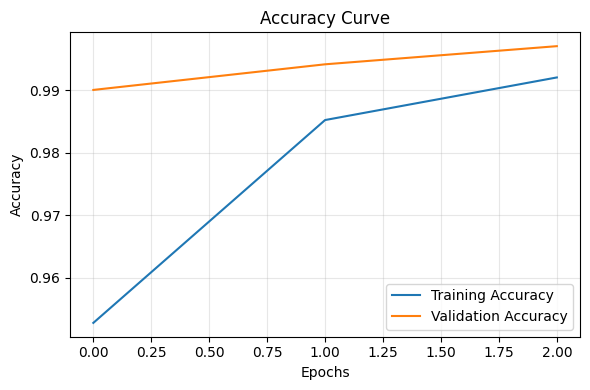

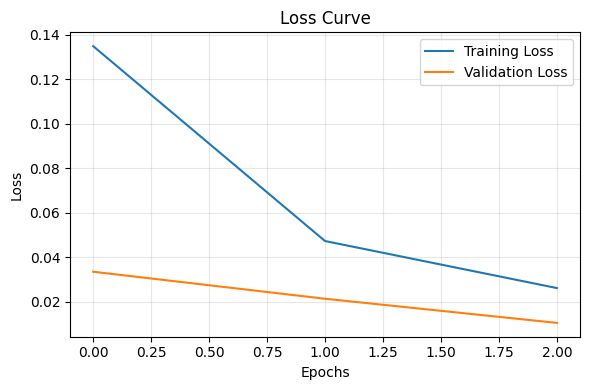

total 1.2M
-rw-r--r-- 1 root root  17K Oct 11 09:03 label_dist_train.png
-rw-r--r-- 1 root root  19K Oct 11 09:03 len_hist_train.png
-rw-r--r-- 1 root root  64K Oct 11 10:40 lstm_accuracy_curve.png
-rw-r--r-- 1 root root  67K Oct 11 10:40 lstm_loss_curve.png
-rw-r--r-- 1 root root  17K Oct 11 09:03 model_comparison.png
-rw-r--r-- 1 root root  13K Oct 11 09:03 tfidf_logreg_performance.png
-rw-r--r-- 1 root root  42K Oct 11 09:03 top_unigrams.png
-rw-r--r-- 1 root root 444K Oct 11 09:03 wc_fake.png
-rw-r--r-- 1 root root 463K Oct 11 09:03 wc_real.png


In [ ]:
# Plot & save training curves (LSTM)
import os, matplotlib.pyplot as plt
os.makedirs("results/figs", exist_ok=True)

# some TF/Keras versions use 'acc' instead of 'accuracy' – handle both
hist = history.history
acc_key = "accuracy" if "accuracy" in hist else "acc"
val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_acc"

# Accuracy curve
plt.figure(figsize=(6,4))
plt.plot(hist[acc_key], label="Training Accuracy")
plt.plot(hist[val_acc_key], label="Validation Accuracy")
plt.title("Accuracy Curve")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/lstm_accuracy_curve.png", dpi=200)
plt.show()

# Loss curve
plt.figure(figsize=(6,4))
plt.plot(hist["loss"], label="Training Loss")
plt.plot(hist["val_loss"], label="Validation Loss")
plt.title("Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/lstm_loss_curve.png", dpi=200)
plt.show()

# Optional: quick confirmation
!ls -lh results/figs | tail -n +1

**Improved LSTM Model**

In [ ]:
import os
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Hyperparameters
VOCAB_SIZE    = 20000
EMBED_DIM     = 128
LSTM_UNITS    = 128
LR            = 1e-3
EPOCHS        = 20
BATCH_SIZE    = 128
DROPOUT_EMB   = 0.2             # Spatial dropout on embeddings
DROPOUT_LSTM  = 0.3             # Dropout on LSTM outputs
REC_DROPOUT   = 0.3             # Recurrent dropout (on LSTM state)
L2_W          = 1e-4            # L2 weight decay on Dense layer

os.makedirs("results/models", exist_ok=True)

# Model (regularized)
model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM),
    SpatialDropout1D(DROPOUT_EMB),  # combats co-adaptation of embedding features

    LSTM(
        LSTM_UNITS,
        dropout=DROPOUT_LSTM,
        recurrent_dropout=REC_DROPOUT,
        return_sequences=False,      # one LSTM block; set True if stacking LSTMs
    ),

    Dropout(0.3),                    # extra regularization before classifier
    Dense(1,
          activation='sigmoid',
          kernel_regularizer=regularizers.l2(L2_W))
])

model.compile(
    loss='binary_crossentropy',
    optimizer=Adam(learning_rate=LR),
    metrics=['accuracy']
)

# Callbacks: prevent overfitting & stabilize training
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-5,
        verbose=1
    ),
    ModelCheckpoint(
        "results/models/lstm_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=0
    )
]

# Train
history = model.fit(
    X_train_pad, train['label'],
    validation_data=(X_val_pad, val['label']),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

# Evaluate/Test
pred_lstm = (model.predict(X_test_pad, verbose=0) > 0.5).astype("int32")

# If 'res' dict doesn't exist yet
if 'res' not in locals():
    res = {}
res['LSTM'] = eval_model('LSTM', test['label'], pred_lstm)

# Quick generalization gap check
hist = history.history
acc_k  = 'accuracy' if 'accuracy' in hist else 'acc'
val_k  = 'val_accuracy' if 'val_accuracy' in hist else 'val_acc'

print(f"Train Acc: {hist[acc_k][-1]:.4f} | Val Acc: {hist[val_k][-1]:.4f} | Gap: {hist[acc_k][-1]-hist[val_k][-1]:+.4f}")
print(f"Train Loss: {hist['loss'][-1]:.4f} | Val Loss: {hist['val_loss'][-1]:.4f} | Gap: {hist['val_loss'][-1]-hist['loss'][-1]:+.4f}")


Epoch 1/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 365s 1s/step - accuracy: 0.8784 - loss: 0.2659 - val_accuracy: 0.9841 - val_loss: 0.0483 - learning_rate: 0.0010
Epoch 2/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 359s 1s/step - accuracy: 0.9846 - loss: 0.0484 - val_accuracy: 0.9941 - val_loss: 0.0196 - learning_rate: 0.0010
Epoch 3/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 359s 1s/step - accuracy: 0.9889 - loss: 0.0351 - val_accuracy: 0.9959 - val_loss: 0.0139 - learning_rate: 0.0010
Epoch 4/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 358s 1s/step - accuracy: 0.9947 - loss: 0.0194 - val_accuracy: 0.9989 - val_loss: 0.0058 - learning_rate: 0.0010
Epoch 5/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 357s 1s/step - accuracy: 0.9971 - loss: 0.0114 - val_accuracy: 0.9991 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 6/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 357s 1s/step - accuracy: 0.9980 - loss: 0.0078 - val_accuracy: 0.9996 - val_loss: 0.0030 - learning_rate: 0.0010
Epoch 7/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 0s 984ms/step - accuracy: 0.9977 - loss: 0

**Model Summary**

In [ ]:
from tensorflow.keras.utils import plot_model

# Display summary table in console
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 300, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,075,141 (30.80 MB)

 Trainable params: 2,691,713 (10.27 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,383,428 (20.54 MB)

**Plot learning curves**

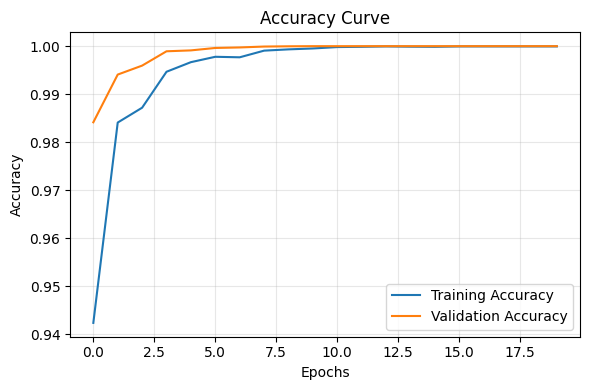

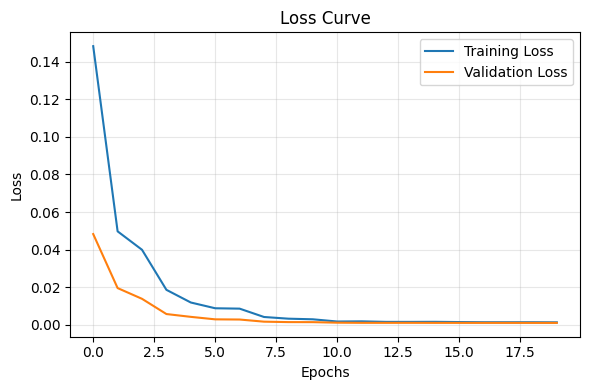

In [ ]:
# Plot & save training curves (LSTM)
import os, matplotlib.pyplot as plt
os.makedirs("results/figs", exist_ok=True)

# some TF/Keras versions use 'acc' instead of 'accuracy' – handle both
hist = history.history
acc_key = "accuracy" if "accuracy" in hist else "acc"
val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_acc"

# Accuracy curve
plt.figure(figsize=(6,4))
plt.plot(hist[acc_key], label="Training Accuracy")
plt.plot(hist[val_acc_key], label="Validation Accuracy")
plt.title("Accuracy Curve")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/lstm_accuracy_curve.png", dpi=200)
plt.show()

# Loss curve
plt.figure(figsize=(6,4))
plt.plot(hist["loss"], label="Training Loss")
plt.plot(hist["val_loss"], label="Validation Loss")
plt.title("Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/lstm_loss_curve.png", dpi=200)
plt.show()



# Model 2 - Bi LSTM

In [ ]:
#import necessary libraries
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout

#Bi LSTM Model Architecture
model_bilstm = Sequential([
    Embedding(input_dim=20000, output_dim=128),
    Bidirectional(LSTM(128, dropout=0.3, recurrent_dropout=0.3)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

#Compile the model
model_bilstm.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

#Train the model
history_bilstm = model_bilstm.fit(
    X_train_pad, train['label'],
    validation_data=(X_val_pad, val['label']),
    epochs=10,
    batch_size=128
)

# Evaluate the model
pred_bilstm = (model_bilstm.predict(X_test_pad) > 0.5).astype('int32')

# Initialize res if it doesn't exist
if 'res' not in locals():
    res = {}

# Log Results
res['BiLSTM'] = eval_model('BiLSTM', test['label'], pred_bilstm)

**Plot learning curves**

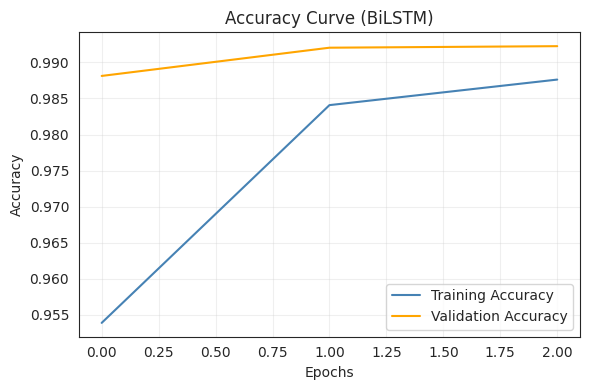

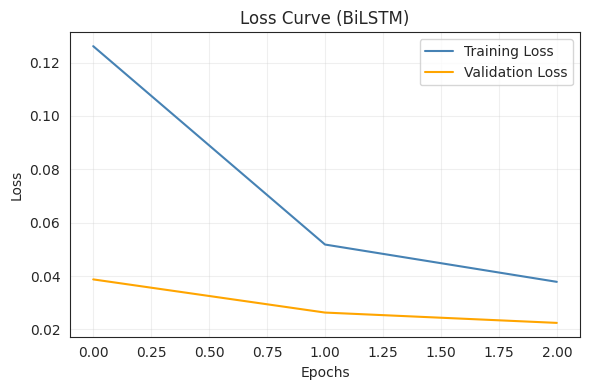

In [ ]:
# Plot & save training curves (BiLSTM)
import os, matplotlib.pyplot as plt
os.makedirs("results/figs", exist_ok=True)

# Extract training history
hist = history_bilstm.history
acc_key = "accuracy" if "accuracy" in hist else "acc"
val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_acc"

# Accuracy Curve
plt.figure(figsize=(6,4))
plt.plot(hist[acc_key], label="Training Accuracy", color='steelblue')
plt.plot(hist[val_acc_key], label="Validation Accuracy", color='orange')
plt.title("Accuracy Curve (BiLSTM)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/bilstm_accuracy_curve.png", dpi=200)
plt.show()

# Loss Curve
plt.figure(figsize=(6,4))
plt.plot(hist["loss"], label="Training Loss", color='steelblue')
plt.plot(hist["val_loss"], label="Validation Loss", color='orange')
plt.title("Loss Curve (BiLSTM)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/bilstm_loss_curve.png", dpi=200)
plt.show()

# Model 3 - RNN

**Basic RNN Model**

In [ ]:
#import necessary libraries
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout

# Model Architecture
model_rnn = Sequential([
    Embedding(input_dim=20000, output_dim=128),
    SimpleRNN(128, activation='tanh', dropout=0.3, recurrent_dropout=0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

# Compile the Model
model_rnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train Model
history_rnn = model_rnn.fit(
    X_train_pad, train['label'],
    validation_data=(X_val_pad, val['label']),
    epochs=3,
    batch_size=128
)

# Evaluate on Test Set
pred_rnn = (model_rnn.predict(X_test_pad) > 0.5).astype('int32')
# Initialize res if it doesn't exist
if 'res' not in locals():
    res = {}

# Log Results
res['SimpleRNN'] = eval_model('SimpleRNN', test['label'], pred_rnn)

Epoch 1/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 203s 680ms/step - accuracy: 0.5729 - loss: 0.6694 - val_accuracy: 0.7646 - val_loss: 0.4781
Epoch 2/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 184s 624ms/step - accuracy: 0.7200 - loss: 0.5191 - val_accuracy: 0.8331 - val_loss: 0.4005
Epoch 3/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 198s 613ms/step - accuracy: 0.7452 - loss: 0.4858 - val_accuracy: 0.7708 - val_loss: 0.4343
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step
SimpleRNN → Accuracy:0.7567, F1:0.6973


**RNN training stability and automatically prevent overfitting or underfitting during training.(Improved RNN Model Implementation)**

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [
    EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5, verbose=1),
]

history_rnn = model_rnn.fit(
    X_train_pad, train['label'],
    validation_data=(X_val_pad, val['label']),
    epochs=20, batch_size=128, callbacks=callbacks, verbose=1
)

# Gap check
hist = history_rnn.history
acc_key = "accuracy" if "accuracy" in hist else "acc"
print(f"Train acc: {hist[acc_key][-1]:.4f} | Val acc: {hist['val_accuracy'][-1]:.4f}")
print(f"Train loss: {hist['loss'][-1]:.4f} | Val loss: {hist['val_loss'][-1]:.4f}")


Epoch 1/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 178s 607ms/step - accuracy: 0.7712 - loss: 0.4580 - val_accuracy: 0.8381 - val_loss: 0.3688 - learning_rate: 0.0010
Epoch 2/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 199s 594ms/step - accuracy: 0.7914 - loss: 0.4284 - val_accuracy: 0.8434 - val_loss: 0.3557 - learning_rate: 0.0010
Epoch 3/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 207s 614ms/step - accuracy: 0.8044 - loss: 0.4126 - val_accuracy: 0.8533 - val_loss: 0.3418 - learning_rate: 0.0010
Epoch 4/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 0s 475ms/step - accuracy: 0.8060 - loss: 0.4134
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
294/294 ━━━━━━━━━━━━━━━━━━━━ 178s 605ms/step - accuracy: 0.8060 - loss: 0.4134 - val_accuracy: 0.8495 - val_loss: 0.3572 - learning_rate: 0.0010
Epoch 5/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - accuracy: 0.8109 - loss: 0.4075
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
294/294 ━━━━━━━━━━━━━━━━━━━━ 181s 616ms/step - accuracy: 0.

**Plot learning curves**

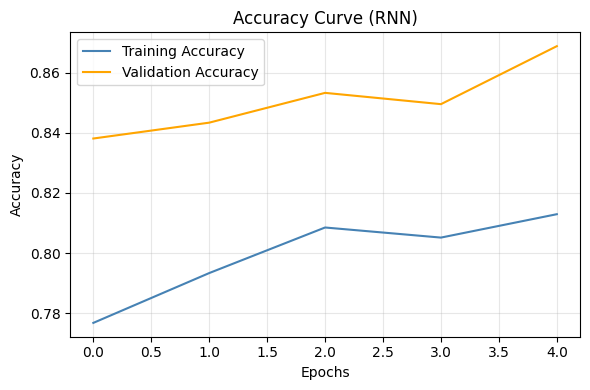

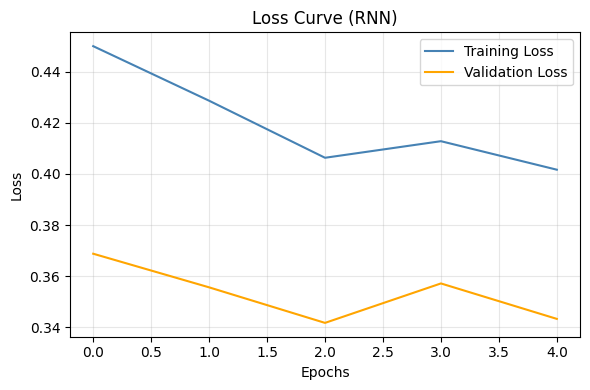

In [ ]:
# Plot & save training curves (RNN)
import os, matplotlib.pyplot as plt
os.makedirs("results/figs", exist_ok=True)

# Extract history dictionary
hist = history_rnn.history
acc_key = "accuracy" if "accuracy" in hist else "acc"
val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_acc"

# Accuracy Curve
plt.figure(figsize=(6,4))
plt.plot(hist[acc_key], label="Training Accuracy", color='steelblue')
plt.plot(hist[val_acc_key], label="Validation Accuracy", color='orange')
plt.title("Accuracy Curve (RNN)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/rnn_accuracy_curve.png", dpi=200)
plt.show()

# Loss Curve
plt.figure(figsize=(6,4))
plt.plot(hist["loss"], label="Training Loss", color='steelblue')
plt.plot(hist["val_loss"], label="Validation Loss", color='orange')
plt.title("Loss Curve (RNN)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/rnn_loss_curve.png", dpi=200)
plt.show()

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_true = test['label'].values
y_pred = pred_rnn.ravel()
print(classification_report(y_true, y_pred, target_names=["Real","Fake"]))
print(confusion_matrix(y_true, y_pred))


              precision    recall  f1-score   support

        Real       0.66      1.00      0.80      2142
        Fake       1.00      0.54      0.70      2347

    accuracy                           0.76      4489
   macro avg       0.83      0.77      0.75      4489
weighted avg       0.84      0.76      0.74      4489

[[2139    3]
 [1089 1258]]


# Model 4 - CNN

**Basic CNN Model**

In [ ]:
#import necessary libraries
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout

#CNN model architecture
model_cnn = Sequential([
    Embedding(input_dim=20000, output_dim=128),
    Conv1D(128, 5, activation='relu'),
    GlobalMaxPooling1D(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

#Compile the model
model_cnn.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

#Train the model
history_cnn = model_cnn.fit(
    X_train_pad, train['label'],
    validation_data=(X_val_pad, val['label']),
    epochs=3,
    batch_size=128
)

# Evaluate
pred_cnn = (model_cnn.predict(X_test_pad) > 0.5).astype('int32')

#Log Results
res['CNN'] = eval_model('CNN', test['label'], pred_cnn)

Epoch 1/8
294/294 ━━━━━━━━━━━━━━━━━━━━ 178s 596ms/step - accuracy: 0.8905 - loss: 0.2407 - val_accuracy: 0.9977 - val_loss: 0.0086
Epoch 2/8
294/294 ━━━━━━━━━━━━━━━━━━━━ 198s 583ms/step - accuracy: 0.9979 - loss: 0.0086 - val_accuracy: 0.9999 - val_loss: 0.0015
Epoch 3/8
294/294 ━━━━━━━━━━━━━━━━━━━━ 169s 576ms/step - accuracy: 0.9998 - loss: 0.0014 - val_accuracy: 1.0000 - val_loss: 1.0675e-04
Epoch 4/8
294/294 ━━━━━━━━━━━━━━━━━━━━ 202s 575ms/step - accuracy: 1.0000 - loss: 2.0023e-04 - val_accuracy: 1.0000 - val_loss: 3.9920e-05
Epoch 5/8
294/294 ━━━━━━━━━━━━━━━━━━━━ 202s 577ms/step - accuracy: 1.0000 - loss: 7.9673e-05 - val_accuracy: 1.0000 - val_loss: 1.8095e-05
Epoch 6/8
294/294 ━━━━━━━━━━━━━━━━━━━━ 169s 576ms/step - accuracy: 1.0000 - loss: 5.2947e-05 - val_accuracy: 1.0000 - val_loss: 1.0808e-05
Epoch 7/8
294/294 ━━━━━━━━━━━━━━━━━━━━ 169s 577ms/step - accuracy: 1.0000 - loss: 3.5503e-05 - val_accuracy: 1.0000 - val_loss: 7.0548e-06
Epoch 8/8
294/294 ━━━━━━━━━━━━━━━━━━━━ 201s 572

**Improved CNN Model**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, SpatialDropout1D, Conv1D, BatchNormalization,
    GlobalMaxPooling1D, Dense, Dropout
)
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Hyperparams to tweak if needed
VOCAB_SIZE   = 20000
EMBED_DIM    = 128
LR           = 1e-3
EPOCHS       = 20
BATCH_SIZE   = 128
L2_W         = 1e-4        # L2 regularization strength
DROPOUT_DENSE= 0.4         # dropout after Dense
SPATIAL_DO   = 0.2         # dropout on embeddings (spatial)
FILTERS      = 128
KERNEL_SIZE  = 5

# Model with regularization layers
model_cnn = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM),
    SpatialDropout1D(SPATIAL_DO),                         # helps generalization on sequence features

    Conv1D(FILTERS, KERNEL_SIZE, activation='relu',
           kernel_regularizer=regularizers.l2(L2_W),      # L2 to reduce overfitting
           padding='valid'),
    BatchNormalization(),                                 # stabilizes/regularizes
    GlobalMaxPooling1D(),

    Dense(64, activation='relu', kernel_regularizer=regularizers.l2(L2_W)),
    Dropout(DROPOUT_DENSE),

    Dense(1, activation='sigmoid')
])

model_cnn.compile(
    loss='binary_crossentropy',
    optimizer=Adam(learning_rate=LR),
    metrics=['accuracy']
)

# Callbacks: stop early + shrink LR when val stalls; keep best weights
callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5, verbose=1),
    ModelCheckpoint("results/models/cnn_best.keras", monitor="val_loss",
                    save_best_only=True, verbose=0)
]

history_cnn = model_cnn.fit(
    X_train_pad, train['label'],
    validation_data=(X_val_pad, val['label']),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,
    shuffle=True
)

# Initialize res if it doesn't exist
if 'res' not in locals():
    res = {}

# Evaluate
pred_cnn = (model_cnn.predict(X_test_pad, verbose=0) > 0.5).astype('int32')
res['CNN'] = eval_model('CNN', test['label'], pred_cnn)

# Quick generalization-gap check
hist = history_cnn.history
acc_key = "accuracy" if "accuracy" in hist else "acc"
val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_acc"
print(f"Train Acc: {hist[acc_key][-1]:.4f} | Val Acc: {hist[val_acc_key][-1]:.4f} | Gap: {hist[acc_key][-1]-hist[val_acc_key][-1]:+.4f}")
print(f"Train Loss: {hist['loss'][-1]:.4f} | Val Loss: {hist['val_loss'][-1]:.4f} | Gap: {hist['val_loss'][-1]-hist['loss'][-1]:+.4f}")

Epoch 1/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 206s 691ms/step - accuracy: 0.8670 - loss: 0.3316 - val_accuracy: 0.9655 - val_loss: 0.2751 - learning_rate: 0.0010
Epoch 2/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 202s 686ms/step - accuracy: 0.9977 - loss: 0.0296 - val_accuracy: 0.9996 - val_loss: 0.0264 - learning_rate: 0.0010
Epoch 3/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 206s 700ms/step - accuracy: 0.9994 - loss: 0.0206 - val_accuracy: 1.0000 - val_loss: 0.0169 - learning_rate: 0.0010
Epoch 4/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 208s 708ms/step - accuracy: 0.9996 - loss: 0.0177 - val_accuracy: 1.0000 - val_loss: 0.0148 - learning_rate: 0.0010
Epoch 5/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 259s 696ms/step - accuracy: 0.9999 - loss: 0.0149 - val_accuracy: 1.0000 - val_loss: 0.0129 - learning_rate: 0.0010
Epoch 6/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 200s 679ms/step - accuracy: 0.9998 - loss: 0.0130 - val_accuracy: 1.0000 - val_loss: 0.0115 - learning_rate: 0.0010
Epoch 7/20
294/294 ━━━━━━━━━━━━━━━━━━━━ 199s 678ms/step - accura

**Plot learning curves**

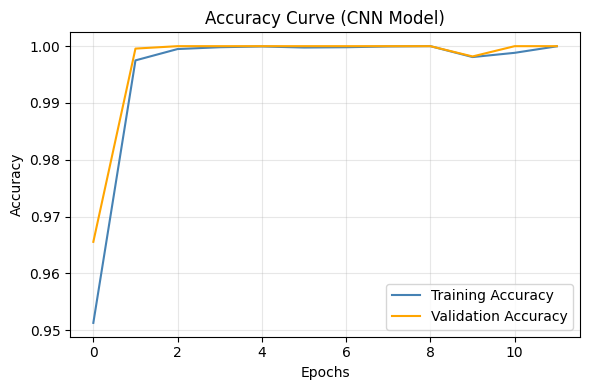

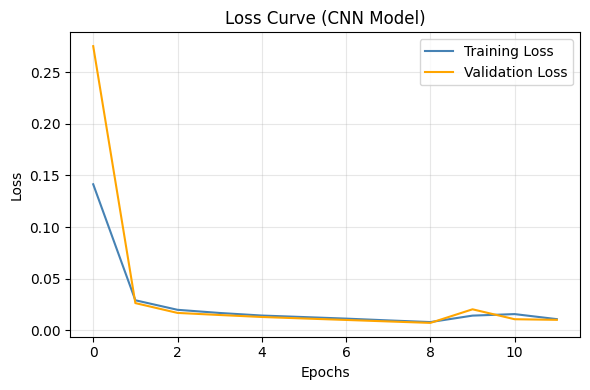

In [ ]:
# Plot & save training curves (CNN)
import os, matplotlib.pyplot as plt
os.makedirs("results/figs", exist_ok=True)

# Extract training history
hist = history_cnn.history
acc_key = "accuracy" if "accuracy" in hist else "acc"
val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_acc"

# Accuracy Curve
plt.figure(figsize=(6,4))
plt.plot(hist[acc_key], label="Training Accuracy", color='steelblue')
plt.plot(hist[val_acc_key], label="Validation Accuracy", color='orange')
plt.title("Accuracy Curve (CNN Model)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/cnn_accuracy_curve.png", dpi=200)
plt.show()

# Loss Curve
plt.figure(figsize=(6,4))
plt.plot(hist["loss"], label="Training Loss", color='steelblue')
plt.plot(hist["val_loss"], label="Validation Loss", color='orange')
plt.title("Loss Curve (CNN Model)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figs/cnn_loss_curve.png", dpi=200)
plt.show()

## Step 5: Save All Trained Models and Artifacts for Deployment

In this step, we save every trained model, vectorizer, and tokenizer so they can be reused. All files are stored in the `results/models/` directory.

In [ ]:
import os
import joblib

# Create directory if not exists
os.makedirs('results/models', exist_ok=True)

# Save Deep Learning Models
# Each model is saved in Keras format (.keras)
# Make sure you already trained them and the variables exist in your notebook
# (model, model_bilstm, model_rnn, model_cnn)

model.save('results/models/lstm_model.keras')           # LSTM
model_bilstm.save('results/models/bilstm_model.keras')  # BiLSTM
model_rnn.save('results/models/simplernn_model.keras')  # RNN
model_cnn.save('results/models/cnn_model.keras')        # CNN

# Save Tokenizer (common across models)
joblib.dump(tokenizer, 'results/models/tokenizer.joblib')

# Verify everything
print("All deep learning models and tokenizer saved in results/models/")
!ls -lh results/models

All deep learning models and tokenizer saved in results/models/
total 129M
-rw-r--r-- 1 root root  33M Oct 11 12:42 bilstm_model.keras
-rw-r--r-- 1 root root  31M Oct 11 12:42 cnn_model.keras
-rw-r--r-- 1 root root  31M Oct 11 12:42 lstm_model.keras
-rw-r--r-- 1 root root  30M Oct 11 12:42 simplernn_model.keras
-rw-r--r-- 1 root root 4.5M Oct 11 12:42 tokenizer.joblib


## Step 6: Backup Models to Google Drive

After successfully training and saving all models, we back them up to Google Drive to ensure the artifacts are safely stored and accessible  
for evaluation.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p '/content/drive/MyDrive/fake_news_project/models'
!cp results/models/* '/content/drive/MyDrive/fake_news_project/models/'
print("Models copied to Google Drive.")

Mounted at /content/drive
Models copied to Google Drive.
